In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [4]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



In [5]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df.columns = df.columns.str.strip().str.lower()

df = df.drop_duplicates()

X = df.drop("target", axis=1)
y = df["target"].astype(int)

print("Dataset shape:", df.shape)
print("Features:", list(X.columns))
print("\nTarget distribution:")
print(y.value_counts())


Dataset shape: (302, 14)
Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


continuous_features = []

for column in X_train.columns:
    if pd.api.types.is_numeric_dtype(X_train[column]):
        if X_train[column].nunique() > 10:
            continuous_features.append(column)

# Remaining features are treated as categorical/discrete
categorical_features = [
    column for column in X_train.columns
    if column not in continuous_features
]

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Continuous features:", continuous_features)
print("Categorical/discrete features:", categorical_features)
print("Training samples:", len(X_train_imputed))
print("Testing samples:", len(X_test_imputed))

Continuous features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical/discrete features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Training samples: 241
Testing samples: 61


In [7]:
model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_imputed, y_train)

normal_predictions = model.predict(X_test_imputed)
normal_probabilities = model.predict_proba(X_test_imputed)

normal_confidence = np.max(normal_probabilities, axis=1)

baseline_accuracy = accuracy_score(y_test, normal_predictions)
baseline_f1 = f1_score(y_test, normal_predictions, zero_division=0)

print("BASELINE MODEL PERFORMANCE")
print("--------------------------")
print("Accuracy:", round(baseline_accuracy, 4))
print("F1 Score:", round(baseline_f1, 4))
print("Average confidence:", round(normal_confidence.mean(), 4))

BASELINE MODEL PERFORMANCE
--------------------------
Accuracy: 0.7705
F1 Score: 0.7879
Average confidence: 0.7926


In [8]:
def create_ood_samples(X_reference, X_samples, direction="high"):
    X_ood = X_samples.copy()

    for column in continuous_features:

        train_values = X_reference[column].dropna()

        q1 = train_values.quantile(0.25)
        q3 = train_values.quantile(0.75)
        iqr = q3 - q1

        train_min = train_values.min()
        train_max = train_values.max()

        lower_limit = train_min - (0.5 * iqr)
        upper_limit = train_max + (0.5 * iqr)

        if direction == "high":
            X_ood[column] = upper_limit

        elif direction == "low":
            X_ood[column] = lower_limit

    return X_ood


print("OOD sample generation function created.")

OOD sample generation function created.


In [9]:
X_ood_high = create_ood_samples(
    X_train_imputed,
    X_test_imputed,
    direction="high"
)

X_ood_low = create_ood_samples(
    X_train_imputed,
    X_test_imputed,
    direction="low"
)


X_ood_mixed = X_test_imputed.copy()

for i in range(len(X_ood_mixed)):
    if i % 2 == 0:
        X_ood_mixed.iloc[i] = X_ood_high.iloc[i]
    else:
        X_ood_mixed.iloc[i] = X_ood_low.iloc[i]

print("Synthetic OOD datasets created.")
print("High OOD shape:", X_ood_high.shape)
print("Low OOD shape:", X_ood_low.shape)
print("Mixed OOD shape:", X_ood_mixed.shape)

Synthetic OOD datasets created.
High OOD shape: (61, 13)
Low OOD shape: (61, 13)
Mixed OOD shape: (61, 13)


In [10]:
def evaluate_ood_dataset(name, X_data, y_true):

    predictions = model.predict(X_data)
    probabilities = model.predict_proba(X_data)

    confidence = np.max(probabilities, axis=1)

    results = {
        "Dataset": name,
        "Accuracy": accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Average Confidence": confidence.mean(),
        "Low Confidence Samples (%)": (
            np.mean(confidence < 0.60) * 100
        ),
        "High Confidence Samples (%)": (
            np.mean(confidence >= 0.80) * 100
        )
    }

    return results, predictions, probabilities


normal_result, normal_predictions, normal_probabilities = (
    evaluate_ood_dataset(
        "Normal Test Data",
        X_test_imputed,
        y_test
    )
)

high_result, high_predictions, high_probabilities = (
    evaluate_ood_dataset(
        "High OOD",
        X_ood_high,
        y_test
    )
)

low_result, low_predictions, low_probabilities = (
    evaluate_ood_dataset(
        "Low OOD",
        X_ood_low,
        y_test
    )
)

mixed_result, mixed_predictions, mixed_probabilities = (
    evaluate_ood_dataset(
        "Mixed OOD",
        X_ood_mixed,
        y_test
    )
)

performance_results = pd.DataFrame([
    normal_result,
    high_result,
    low_result,
    mixed_result
])

print(performance_results.round(4))

            Dataset  Accuracy  Precision  Recall  F1 Score  \
0  Normal Test Data    0.7705     0.7879  0.7879    0.7879   
1          High OOD    0.7869     0.7632  0.8788    0.8169   
2           Low OOD    0.8361     0.8108  0.9091    0.8571   
3         Mixed OOD    0.8197     0.8056  0.8788    0.8406   

   Average Confidence  Low Confidence Samples (%)  High Confidence Samples (%)  
0              0.7926                     14.7541                      52.4590  
1              0.6496                     21.3115                       1.6393  
2              0.6598                     27.8689                       4.9180  
3              0.6631                     26.2295                       4.9180  


In [11]:
baseline = performance_results.iloc[0]

comparison = performance_results.copy()

comparison["Accuracy Change"] = (
    comparison["Accuracy"] - baseline["Accuracy"]
)

comparison["F1 Change"] = (
    comparison["F1 Score"] - baseline["F1 Score"]
)

comparison["Confidence Change"] = (
    comparison["Average Confidence"]
    - baseline["Average Confidence"]
)

print("PERFORMANCE CHANGE UNDER OOD DATA")
print("---------------------------------")

print(
    comparison[
        [
            "Dataset",
            "Accuracy Change",
            "F1 Change",
            "Confidence Change"
        ]
    ].round(4)
)

PERFORMANCE CHANGE UNDER OOD DATA
---------------------------------
            Dataset  Accuracy Change  F1 Change  Confidence Change
0  Normal Test Data           0.0000     0.0000             0.0000
1          High OOD           0.0164     0.0290            -0.1430
2           Low OOD           0.0656     0.0693            -0.1328
3         Mixed OOD           0.0492     0.0527            -0.1295


CONFIDENCE SUMMARY
------------------
                    mean  median     min     max     std
Dataset                                                 
High OOD          0.6496  0.6553  0.5133  0.8000  0.0719
Low OOD           0.6598  0.6752  0.5010  0.8503  0.0926
Mixed OOD         0.6631  0.6740  0.5042  0.8503  0.0855
Normal Test Data  0.7926  0.8126  0.5100  1.0000  0.1457


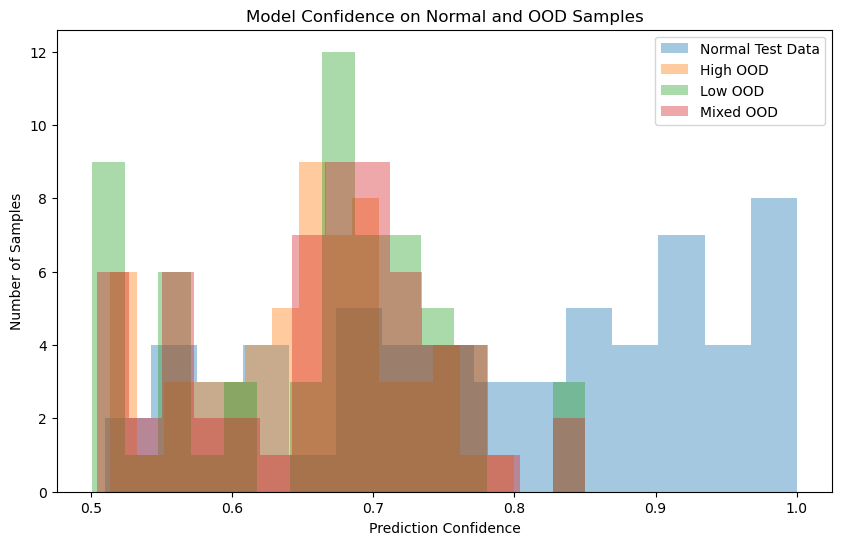

In [12]:
confidence_results = pd.DataFrame({
    "Dataset": (
        ["Normal Test Data"] * len(normal_confidence)
        + ["High OOD"] * len(high_probabilities)
        + ["Low OOD"] * len(low_probabilities)
        + ["Mixed OOD"] * len(mixed_probabilities)
    ),

    "Confidence": np.concatenate([
        np.max(normal_probabilities, axis=1),
        np.max(high_probabilities, axis=1),
        np.max(low_probabilities, axis=1),
        np.max(mixed_probabilities, axis=1)
    ])
})

print("CONFIDENCE SUMMARY")
print("------------------")

print(
    confidence_results.groupby("Dataset")["Confidence"]
    .agg(["mean", "median", "min", "max", "std"])
    .round(4)
)

plt.figure(figsize=(10, 6))

for name in confidence_results["Dataset"].unique():
    values = confidence_results.loc[
        confidence_results["Dataset"] == name,
        "Confidence"
    ]

    plt.hist(
        values,
        bins=15,
        alpha=0.4,
        label=name
    )

plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")
plt.title("Model Confidence on Normal and OOD Samples")
plt.legend()
plt.show()

In [13]:
def find_confident_errors(name, predictions, probabilities, y_true):

    confidence = np.max(probabilities, axis=1)

    error_data = pd.DataFrame({
        "Dataset": name,
        "Actual": np.asarray(y_true),
        "Predicted": predictions,
        "Confidence": confidence
    })

    error_data["Correct"] = (
        error_data["Actual"] == error_data["Predicted"]
    )

    confident_errors = error_data[
        (error_data["Correct"] == False)
        & (error_data["Confidence"] >= 0.80)
    ]

    return error_data, confident_errors


normal_errors, normal_confident_errors = find_confident_errors(
    "Normal Test Data",
    normal_predictions,
    normal_probabilities,
    y_test
)

high_errors, high_confident_errors = find_confident_errors(
    "High OOD",
    high_predictions,
    high_probabilities,
    y_test
)

low_errors, low_confident_errors = find_confident_errors(
    "Low OOD",
    low_predictions,
    low_probabilities,
    y_test
)

mixed_errors, mixed_confident_errors = find_confident_errors(
    "Mixed OOD",
    mixed_predictions,
    mixed_probabilities,
    y_test
)

all_confident_errors = pd.concat([
    normal_confident_errors,
    high_confident_errors,
    low_confident_errors,
    mixed_confident_errors
], ignore_index=True)

print("HIGH-CONFIDENCE INCORRECT PREDICTIONS")
print("------------------------------------")
print(all_confident_errors.head(20))

print("\nTotal high-confidence errors:", len(all_confident_errors))

HIGH-CONFIDENCE INCORRECT PREDICTIONS
------------------------------------
            Dataset  Actual  Predicted  Confidence  Correct
0  Normal Test Data       0          1    0.860431    False
1  Normal Test Data       1          0    0.926667    False

Total high-confidence errors: 2


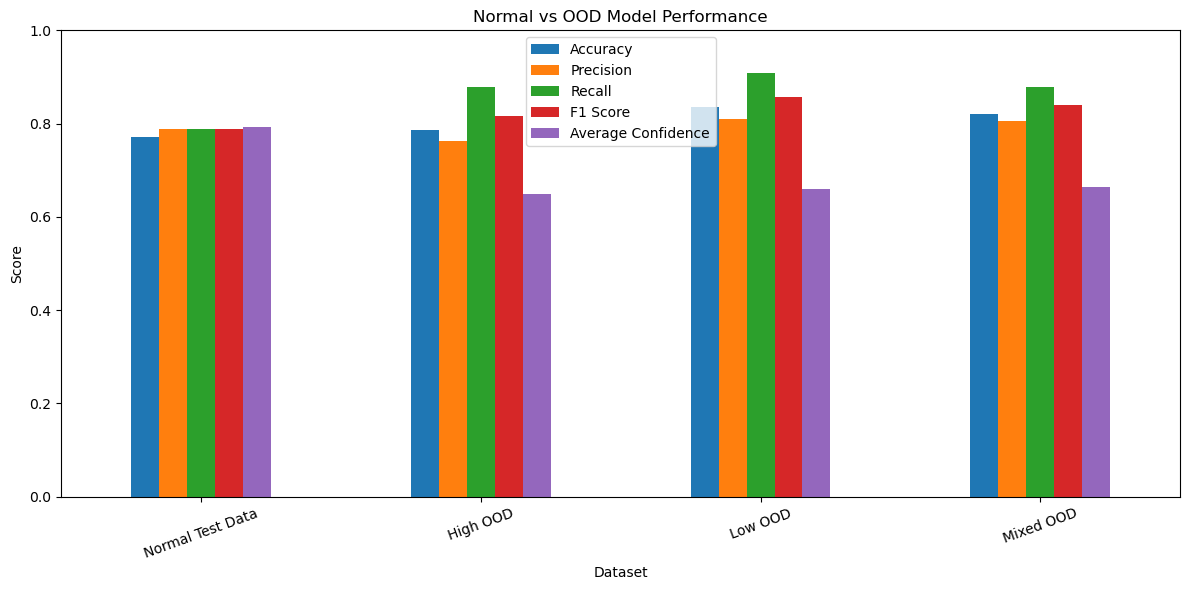

In [14]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "Average Confidence"
]

performance_results.set_index("Dataset")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Normal vs OOD Model Performance")
plt.ylabel("Score")
plt.xlabel("Dataset")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

In [15]:
generalization_report = performance_results.copy()

generalization_report["Accuracy Retention (%)"] = (
    generalization_report["Accuracy"]
    / max(baseline["Accuracy"], 1e-10)
) * 100

generalization_report["F1 Retention (%)"] = (
    generalization_report["F1 Score"]
    / max(baseline["F1 Score"], 1e-10)
) * 100

print("GENERALIZATION REPORT")
print("---------------------")

print(
    generalization_report[
        [
            "Dataset",
            "Accuracy",
            "F1 Score",
            "Average Confidence",
            "Accuracy Retention (%)",
            "F1 Retention (%)"
        ]
    ].round(2)
)

GENERALIZATION REPORT
---------------------
            Dataset  Accuracy  F1 Score  Average Confidence  \
0  Normal Test Data      0.77      0.79                0.79   
1          High OOD      0.79      0.82                0.65   
2           Low OOD      0.84      0.86                0.66   
3         Mixed OOD      0.82      0.84                0.66   

   Accuracy Retention (%)  F1 Retention (%)  
0                  100.00            100.00  
1                  102.13            103.68  
2                  108.51            108.79  
3                  106.38            106.69  


In [16]:
performance_results.to_csv(
    "ood_performance_results.csv",
    index=False
)

comparison.to_csv(
    "ood_performance_comparison.csv",
    index=False
)

confidence_results.to_csv(
    "ood_confidence_results.csv",
    index=False
)

all_confident_errors.to_csv(
    "ood_confident_errors.csv",
    index=False
)

generalization_report.to_csv(
    "ood_generalization_report.csv",
    index=False
)

print("All OOD testing reports saved successfully.")

All OOD testing reports saved successfully.
